In [1]:
from pricing import *
from test_pricing import *

In [2]:
from matplotlib import pyplot as plt
import seaborn; seaborn.set()
import numpy as np

In [3]:
%matplotlib inline

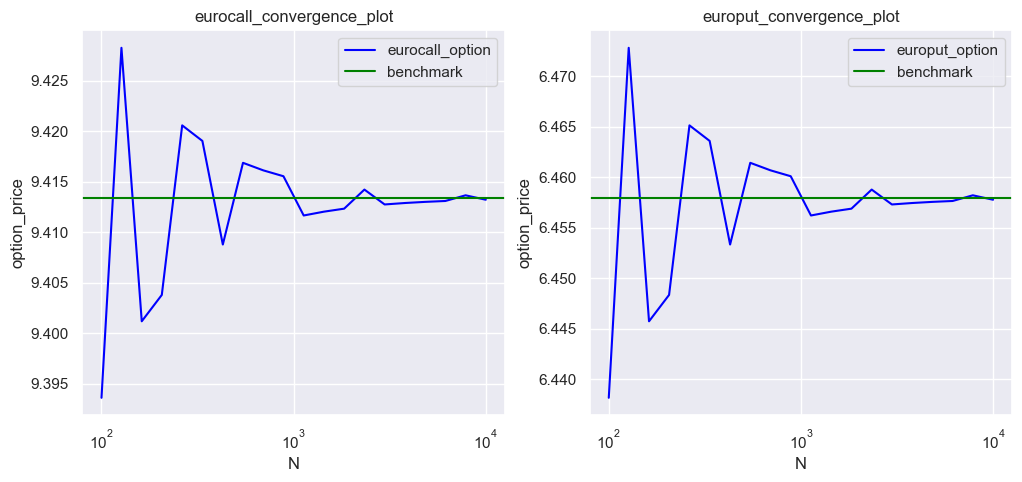

In [14]:
#convergence plots
S0 = 100; E = 100; r = 0.03 / 252; sig = 0.20 / np.sqrt(252); T = 252
N_values = np.logspace(2, 4, 20, dtype = int)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
Call = []
for N in N_values:
    x = price_option(S0, E, r, sig, T, N = N)
    Call.append(x[0])
Cmark = eurocallbenchmark(E, S0, r, sig, T)
ax[0].plot(N_values, Call, color = 'blue', label = 'eurocall_option')
ax[0].axhline(y = Cmark, color = 'green', label = 'benchmark')
ax[0].legend()
ax[0].set_title('eurocall_convergence_plot')
ax[0].set_xlabel('N')
ax[0].set_ylabel('option_price')
ax[0].set_xscale('log')

Put = []
for N in N_values:
    x = price_option(S0, E, r, sig, T, 
                     i = 0,
                     N = N,
                     option_type='put')
    Put.append(x[0])
Pmark = europutbenchmark(E, S0, r, sig, T)
ax[1].plot(N_values, Put, color = 'blue', label = 'europut_option')
ax[1].axhline(y = Pmark, color = 'green', label = 'benchmark')
ax[1].legend()
ax[1].set_title('europut_convergence_plot')
ax[1].set_xlabel('N')
ax[1].set_ylabel('option_price')
ax[1].set_xscale('log')

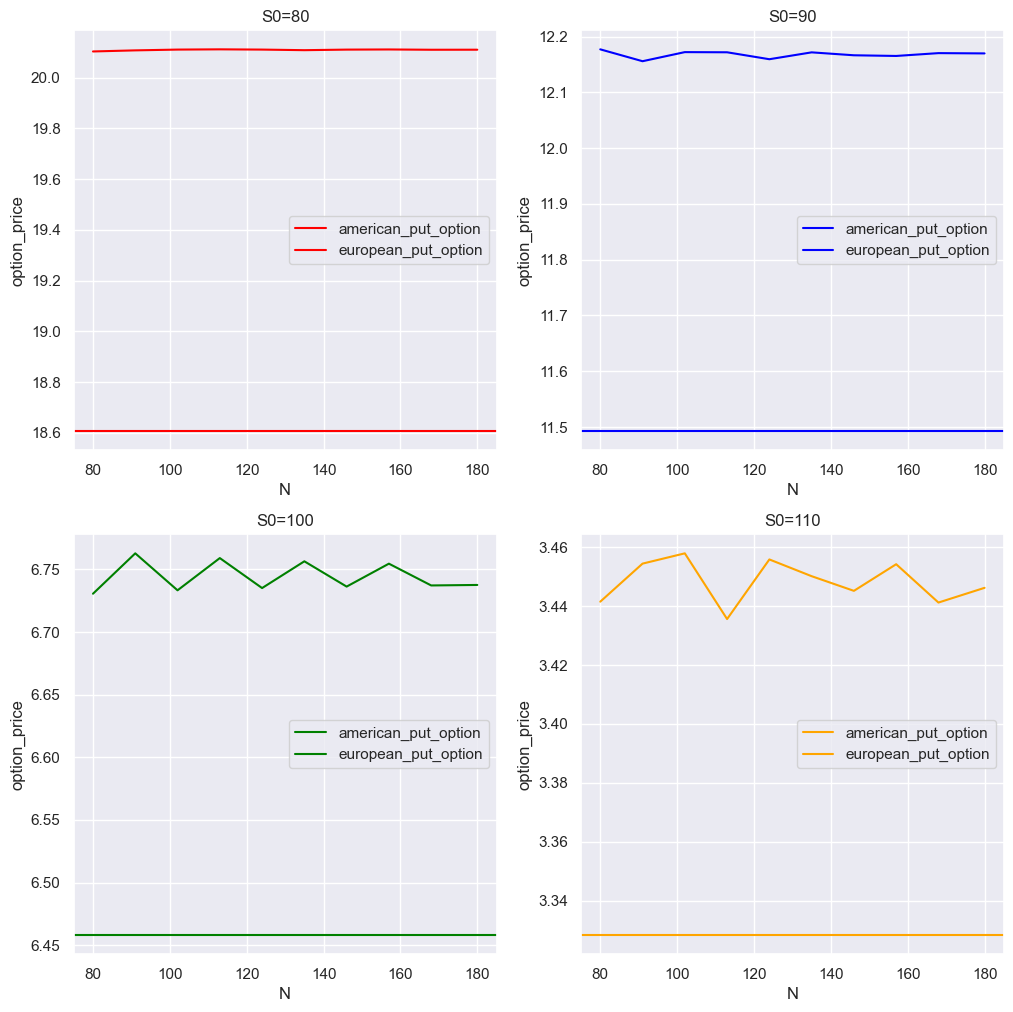

In [20]:
# compare american put option price and europut option price
S0_values = [80, 90, 100, 110] 
E = 100; r = 0.03 / 252; sig = 0.20 / np.sqrt(252)
T = 252
N_values = np.linspace(80, 180, 10, dtype = int)

color = ['red', 'blue', 'green', 'orange']
title = ['S0=80', 'S0=90', 'S0=100', 'S0=110']

fig, ax = plt.subplots(2, 2, figsize=(12, 12))
ax = ax.flatten()
for i, s in enumerate(S0_values):
    EP = europutbenchmark(E, s, r, sig, T)
    Put = []
    for N in N_values:
        x = price_option(s, E, r, sig, T,
                         i = 0,
                         N = N,
                         option_type='put',
                         option_style='american')
        Put.append(x[0])
    ax[i].plot(N_values, Put, color = color[i], label = 'american_put_option')
    ax[i].axhline(y = EP, color = color[i], label = 'european_put_option')
    ax[i].set_xlabel('N')
    ax[i].set_ylabel('option_price')
    ax[i].set_title(title[i])
    ax[i].legend()

Text(0, 0.5, 'option_price')

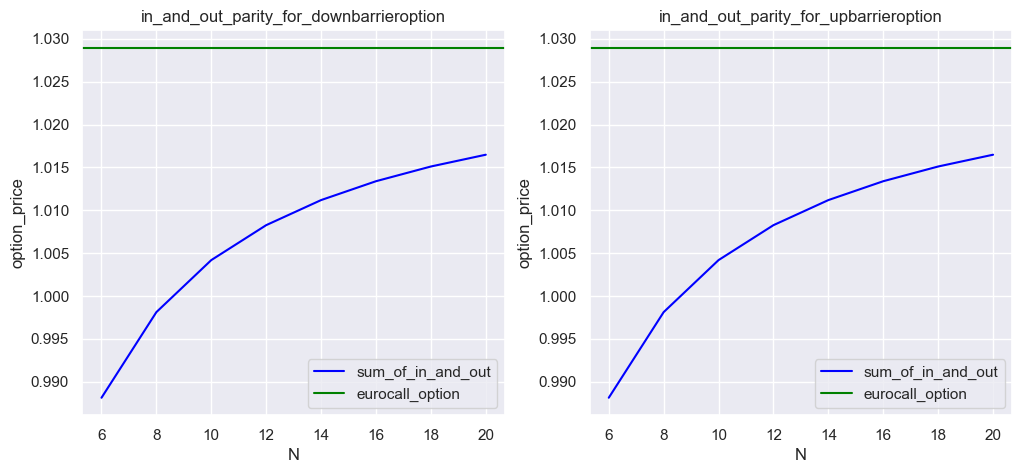

In [25]:
#check the in_out parity of barrier_option:
S0 = 100; E = 100; r = 0.03 / 252; sig = 0.20 / np.sqrt(252); T = 4
N_values = [6, 8, 10, 12, 14, 16, 18, 20]
down_barrier = 98
up_barrier = 102

fig, ax = plt.subplots(1, 2, figsize = (12, 5))
Y = []
for N in N_values:
    x = price_option(S0, E, r, sig, T, 
                    i = 0,
                    N = N,
                    option_style='barrier',
                    barrier=down_barrier,
                    barrier_type='down_and_out')
    y = price_option(S0, E, r, sig, T, 
                    i = 0,
                    N = N,
                    option_style='barrier',
                    barrier=down_barrier,
                    barrier_type='down_and_in')

    s = x + y
    Y.append(s)

cmark = eurocallbenchmark(E, S0, r, sig, T)
ax[0].plot(N_values, Y, color = 'blue', label = 'sum_of_in_and_out')
ax[0].axhline(y = cmark, color = 'green', label = 'eurocall_option')
ax[0].legend()
ax[0].set_title('in_and_out_parity_for_downbarrieroption')
ax[0].set_xlabel('N')
ax[0].set_ylabel('option_price')

Y = []
for N in N_values:
    x = price_option(S0, E, r, sig, T, 
                    i = 0,
                    N = N,
                    option_style='barrier',
                    barrier=up_barrier,
                    barrier_type='up_and_out')
    y = price_option(S0, E, r, sig, T, 
                    i = 0,
                    N = N,
                    option_style='barrier',
                    barrier=up_barrier,
                    barrier_type='up_and_in')

    s = x + y
    Y.append(s)

ax[1].plot(N_values, Y, color = 'blue', label = 'sum_of_in_and_out')
ax[1].axhline(y = cmark, color = 'green', label = 'eurocall_option')
ax[1].legend()
ax[1].set_title('in_and_out_parity_for_upbarrieroption')
ax[1].set_xlabel('N')
ax[1].set_ylabel('option_price')

Text(0, 0.5, 'option_price')

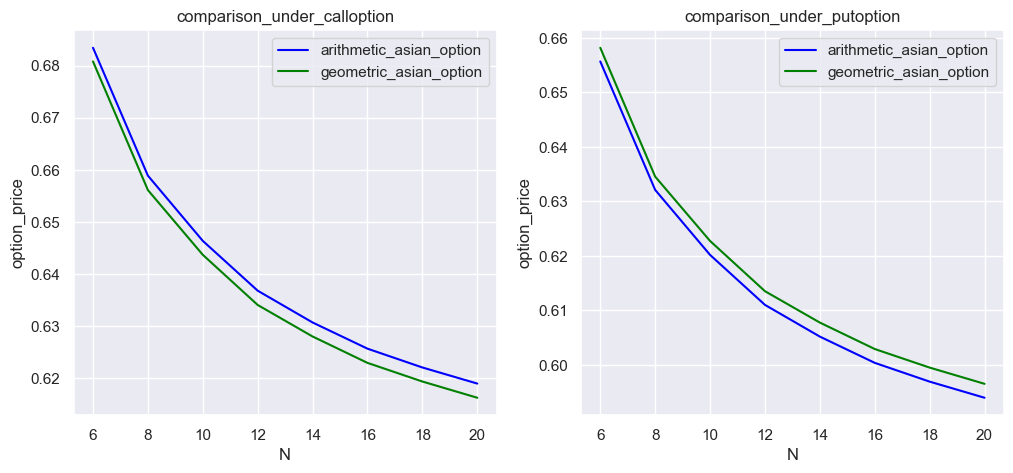

In [29]:
#compare asian geometric option and asian arithmetic option
S0 = 100; E = 100; r = 0.03 / 252; sig = 0.20 / np.sqrt(252); T = 4
N_values = [6, 8, 10, 12, 14, 16, 18, 20]

fig, ax = plt.subplots(1, 2, figsize = (12, 5))
X, Y = [], []
for N in N_values:
    x = price_option(S0, E, r, sig, T, 
                    i = 0,
                    N = N,
                    option_type='call',
                    option_style='asian',
                    asian_average='arithmetic')
    y = price_option(S0, E, r, sig, T, 
                    i = 0,
                    N = N,
                    option_type='call',
                    option_style='asian',
                    asian_average='geometric')

    X.append(x[0])
    Y.append(y[0])

ax[0].plot(N_values, X, color = 'blue', label = 'arithmetic_asian_option')
ax[0].plot(N_values, Y, color = 'green', label = 'geometric_asian_option')
ax[0].legend()
ax[0].set_title('comparison_under_calloption')
ax[0].set_xlabel('N')
ax[0].set_ylabel('option_price')

X, Y = [], []
for N in N_values:
    x = price_option(S0, E, r, sig, T, 
                    i = 0,
                    N = N,
                    option_type='put',
                    option_style='asian',
                    asian_average='arithmetic')
    y = price_option(S0, E, r, sig, T, 
                    i = 0,
                    N = N,
                    option_type='put',
                    option_style='asian',
                    asian_average='geometric')

    X.append(x[0])
    Y.append(y[0])

ax[1].plot(N_values, X, color = 'blue', label = 'arithmetic_asian_option')
ax[1].plot(N_values, Y, color = 'green', label = 'geometric_asian_option')
ax[1].legend()
ax[1].set_title('comparison_under_putoption')
ax[1].set_xlabel('N')
ax[1].set_ylabel('option_price')

In [4]:
from greeks import *

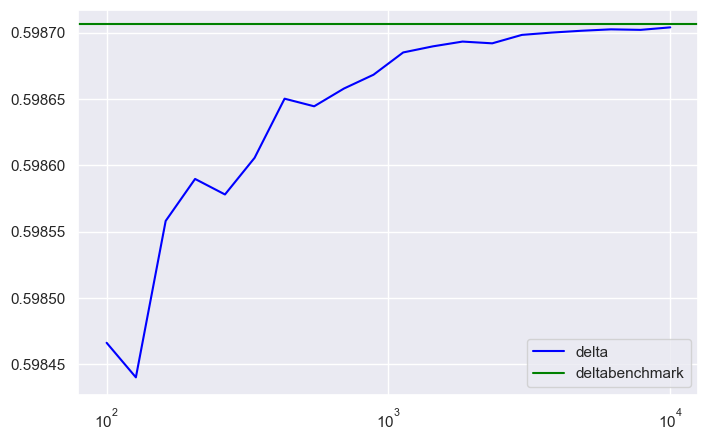

In [ ]:
#accuracy validation of delta for eurocalloption
S0 = 100; E = 100; r = 0.03 / 252; sig = 0.20 / np.sqrt(252); T = 252
N_values = np.logspace(2, 4, 20, dtype = int)

X = []
for N in N_values:
    de = delta(S0, E, r, sig, T, 0, 
               h = None,
               N = N)['expected_delta']
    X.append(de)

deltamark = deltacall(E, S0, r, sig, T)

plt.figure(figsize = (8, 5))
plt.plot(N_values, X, color = 'blue', label = 'delta')
plt.axhline(y = deltamark, color = 'green', label = 'deltabenchmark')
plt.legend()
plt.xscale('log')

Text(0.5, 1.0, 'bump_stability_of_gamma_for_arithmeticasian')

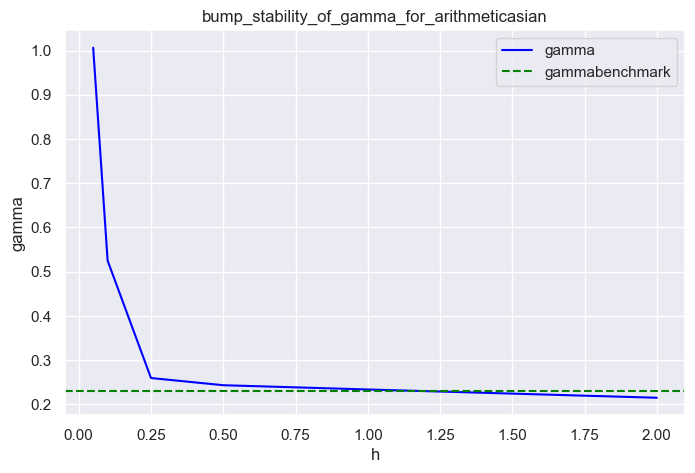

In [9]:
#bump stability of gamma for arithmetic asian option
S0 = 100; E = 100; r = 0.03 / 252; sig = 0.20 / np.sqrt(252); T = 4; N = 8
h_values = [0.05, 0.1, 0.25, 0.5, 1.0, 2.0]

X = []
for h in h_values:
    ga = gamma(S0, E, r, sig, T, 0, h, N,
               option_type='call',
               option_style='asian',
               asian_average='arithmetic')['expected_gamma']
    X.append(ga)

plt.figure(figsize = (8, 5))
plt.plot(h_values, X, color = 'blue', label = 'gamma')
plt.axhline(y = 0.23, color = 'green', linestyle = '--', label = 'gammabenchmark')
plt.legend()
plt.xlabel('h')
plt.ylabel('gamma')
plt.title('bump_stability_of_gamma_for_arithmeticasian')

Text(0.5, 1.0, 'bump_stability_of_vega_for_geometricasian')

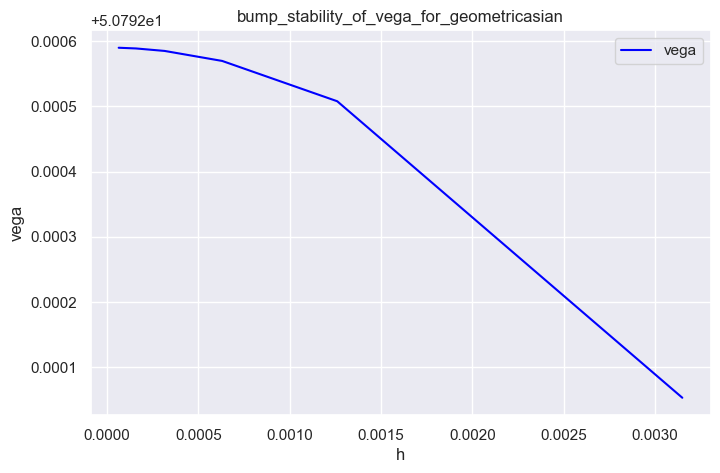

In [16]:
#bump stability of vega for geometric asian option
S0 = 100; E = 100; r = 0.03 / 252; sig = 0.20 / np.sqrt(252); T = 4; N = 8
h_values = np.array([0.001, 0.0025, 0.005, 0.01, 0.02, 0.05]) / np.sqrt(252)

X = []
for h in h_values:
    ve = vega(S0, E, r, sig, T, 0, h, N,
               option_type='call',
               option_style='asian',
               asian_average='geometric')['expected_vega']
    X.append(ve)
    
plt.figure(figsize = (8, 5))
plt.plot(h_values, X, color = 'blue', label = 'vega')
plt.legend()
plt.xlabel('h')
plt.ylabel('vega')
plt.title('bump_stability_of_vega_for_geometricasian')

Text(0.5, 1.0, 'theta_vs_barrier_level')

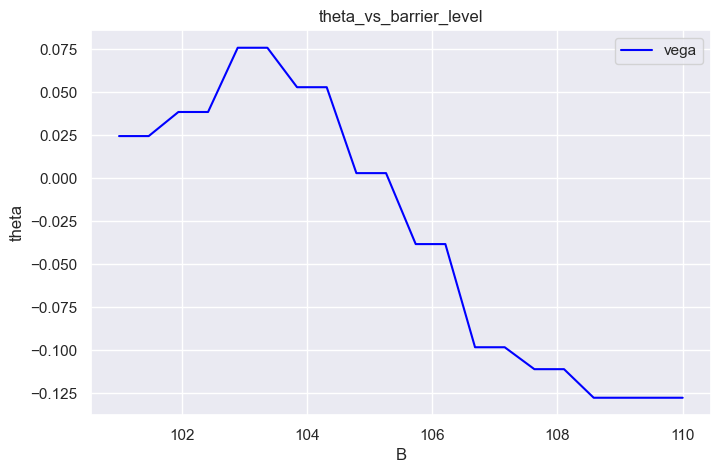

In [18]:
S0 = 100; E = 100; r = 0.03 / 252; sig = 0.20 / np.sqrt(252); T = 4; N = 8
B_values = np.linspace(101, 110, 20)

X = []
for B in B_values:
    th = theta(S0, E, r, sig, T, 0, N,
               option_type='call',
               option_style='barrier',
               barrier = B,
               barrier_type='up_and_out')['expected_theta']
    X.append(th)
    
plt.figure(figsize = (8, 5))
plt.plot(B_values, X, color = 'blue', label = 'vega')
plt.legend()
plt.xlabel('B')
plt.ylabel('theta')
plt.title('theta_vs_barrier_level')